# AWS Global Infrastructure: Regions, AZs, data centers and edge locations

**Goal:** by the end of this lesson you can explain how AWS is built around the world, use the AWS CLI to look at Regions and Availability Zones, and understand why the same service costs different amounts in different Regions.

| Part | Topic |
|---|---|
| 0 | Set up the CLI inside the notebook |
| 1 | The big picture (one simple drawing) |
| 2 | Regions |
| 3 | Availability Zones (AZs) |
| 4 | Data centers |
| 5 | Edge locations |
| 6 | What is global, what is regional, what lives in one AZ |
| 7 | Why prices change from Region to Region (with a database example) |
| 8 | How to choose a Region |
| 9 | Clean-up |
| 10 | Exercises |

> **Before you start:** you need an AWS account and a user with administrator permissions (not the *root* user). This lesson only **reads** information from AWS. It **creates nothing** and costs **nothing**.

### How to use this notebook
- A notebook has **text cells** (like this one) and **code cells**.
- To run a code cell: click it and press **Shift + Enter**.
- Run the cells **in order**, from top to bottom.
- When a line starts with **`!`**, it is a terminal command: exactly what you would type in your computer's terminal, just without the `!`.

---
## Part 0: Set up the CLI

The **AWS CLI** is a program that lets you give orders to AWS by typing commands instead of clicking around the website (the *console*).

The cell below checks whether the CLI is already installed. If it is not, it installs it (this automatic install only works on Linux, e.g. Google Colab. On your own computer, follow the README).

In [ ]:
!aws --version 2>/dev/null || (curl -s "https://awscli.amazonaws.com/awscli-exe-linux-x86_64.zip" -o /tmp/awscliv2.zip && unzip -q -o /tmp/awscliv2.zip -d /tmp && /tmp/aws/install --update && aws --version)

### Log in (without leaving your keys in the notebook)

The CLI needs your *access key ID* and your *secret access key* to know **who you are**.

⚠️ **Never paste your keys straight into a cell.** The notebook is saved and may be shared. That is why we use `getpass`, which asks for the key in a hidden box and saves nothing in the file.

In [ ]:
import os, json, subprocess
from getpass import getpass

os.environ["AWS_ACCESS_KEY_ID"] = getpass("Access key ID: ")
os.environ["AWS_SECRET_ACCESS_KEY"] = getpass("Secret access key: ")
os.environ["AWS_DEFAULT_REGION"] = "eu-west-1"   # Ireland. The CLI always needs a "home" Region.
os.environ["AWS_PAGER"] = ""                      # prints everything at once, without paging

print("Done! Keys kept only in this session's memory.")

First test: ask AWS **"who am I?"**. If you see your account number and your user, everything works.

In [ ]:
!aws sts get-caller-identity

A small helper that runs a CLI command and gives the answer back as Python data (you do not need to understand its code right now):

In [ ]:
def aws_json(command):
    '''Runs a CLI command and returns the answer as Python data.'''
    r = subprocess.run("aws " + command + " --output json", shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(r.stderr)
    return json.loads(r.stdout) if r.stdout.strip() else {}

---
## Part 1: The big picture

Think of a company that sells products in many countries.

| In the company | In AWS | What it is |
|---|---|---|
| A **city** where the company works | **Region** | A place in the world, like Ireland, Frankfurt or São Paulo |
| A **neighbourhood** of that city, with its own power and water | **Availability Zone (AZ)** | A separate part of a Region. If one has a problem, the others keep working |
| The **buildings** in that neighbourhood | **Data center** | The real building full of servers |
| **Small corner shops** around the world that keep copies of popular products | **Edge location** | A small AWS site close to users that keeps copies of your content |

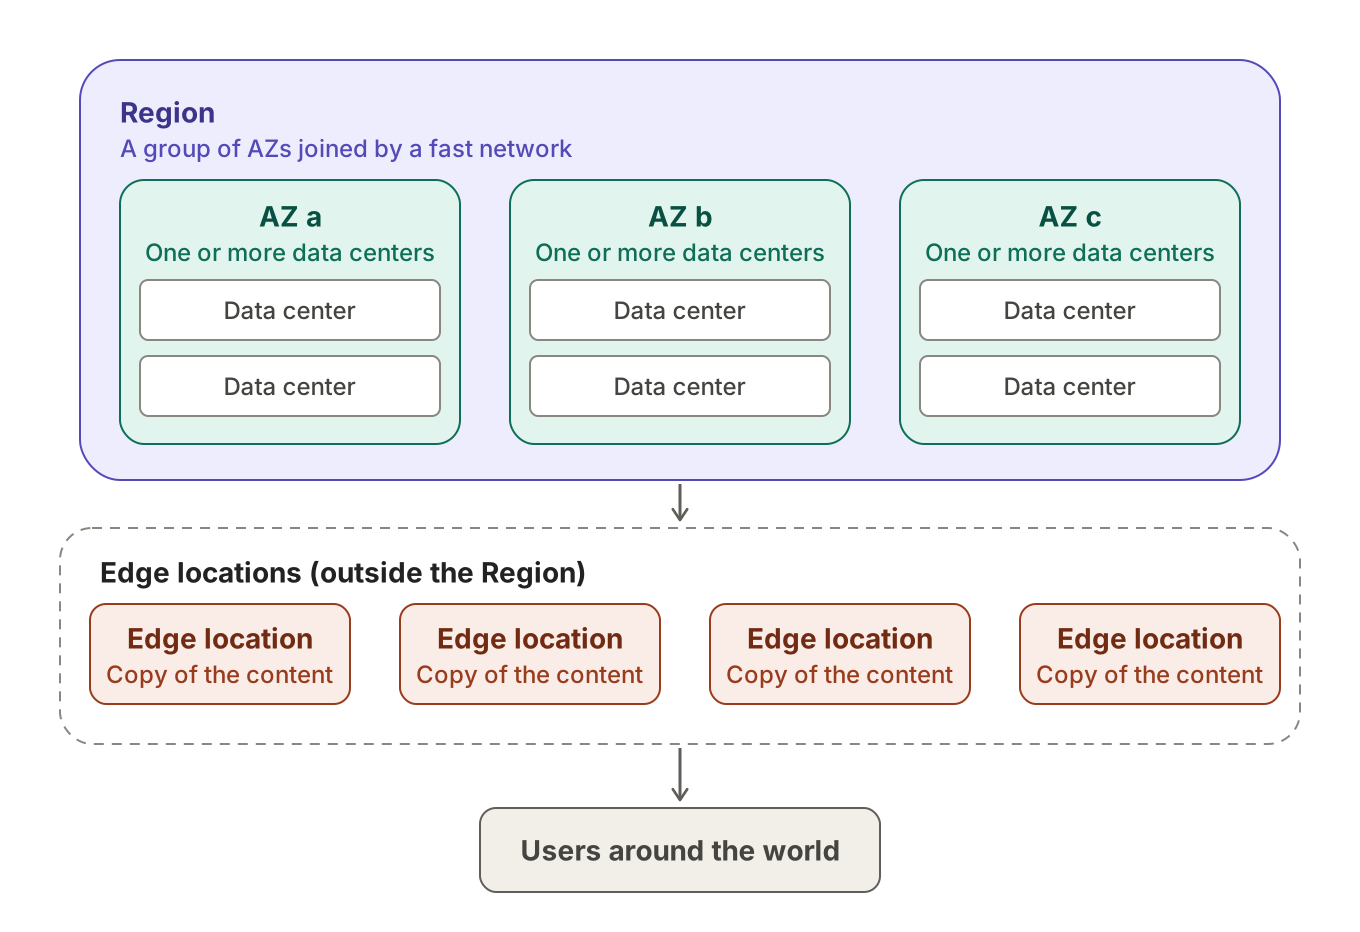

Example: the Region of Ireland (`eu-west-1`) has the AZs `eu-west-1a`, `eu-west-1b` and `eu-west-1c`, each one with one or more data centers. The edge locations are many small sites around the world. They are **not** inside a Region and **not** inside an AZ.

The rule to remember: **Region > AZ > data center.** Edge locations live in a different group.

---
## Part 2: Regions

A **Region** is a place in the world where AWS has groups of data centers. Every Region has:
- a **name** people read, like *Europe (Ireland)*,
- a **code** used in commands, like `eu-west-1`.

Two important facts:
1. **Regions are independent.** Your data is **not** copied to another Region unless you ask for it.
2. **Not every Region is turned on by default.** Newer Regions are *opt-in*: you must enable them in your account first.

Let us ask AWS for the Regions **enabled in your account**:

In [ ]:
!aws ec2 describe-regions --query "Regions[].[RegionName,OptInStatus]" --output table

Now **all** Regions, including the ones that are not enabled yet. Look at the `OptInStatus` column:
- `opt-in-not-required`: always on.
- `opted-in`: you turned it on.
- `not-opted-in`: exists, but is off for your account.

In [ ]:
!aws ec2 describe-regions --all-regions --query "Regions[].[RegionName,OptInStatus]" --output table

---
## Part 3: Availability Zones (AZs)

An **Availability Zone** is a part of a Region. It is made of **one or more data centers**.

Why have AZs at all? Imagine all your servers are in one building and there is a power cut. Everything stops. If your servers are spread over **two AZs** and one has a power cut, the other keeps working.

AWS builds AZs with two goals that pull in opposite directions:
- **Far enough apart** that one problem (fire, flood, power cut) does not hit two AZs.
- **Close enough** that a very fast network connects them, so your servers can talk to each other with almost no delay.

Each Region has **at least three** AZs. Let us look at the AZs of Ireland:

In [ ]:
!aws ec2 describe-availability-zones --region eu-west-1 --filters Name=zone-type,Values=availability-zone --query "AvailabilityZones[].[ZoneName,ZoneId,State]" --output table

### Name or ID?

You see two codes for each AZ:
- **ZoneName**, like `eu-west-1a`: the name you type in commands.
- **ZoneId**, like `euw1-az1`: the code of the **real physical place**. It is the same in every account.

Why two? In older accounts, AWS gave the name `eu-west-1a` to **different physical places in different accounts**, to avoid everybody crowding the first AZ. (AWS changed this for accounts created from November 2025, but older accounts still work the old way.) So if two companies want to talk about the *same* physical AZ, they must compare the **ZoneId**, not the name.

### How many AZs does each Region have?

The cell below asks every Region enabled in your account and draws a bar for each. It takes about 20 to 40 seconds.

In [ ]:
from concurrent.futures import ThreadPoolExecutor

regions = [r["RegionName"] for r in aws_json("ec2 describe-regions")["Regions"]]

def count_azs(region):
    zones = aws_json(f"ec2 describe-availability-zones --region {region} --filters Name=zone-type,Values=availability-zone")["AvailabilityZones"]
    return region, len(zones)

with ThreadPoolExecutor(max_workers=8) as pool:
    results = sorted(pool.map(count_azs, regions))

for region, n in results:
    print(f"{region:<18} {'█' * n}  {n} AZs")

print(f"\nTotal: {sum(n for _, n in results)} AZs in {len(results)} Regions (the ones enabled in your account).")

### Extensions: Local Zones

Besides normal AZs, AWS has **Local Zones**: small extensions of a Region placed inside a big city, to be closer to the people there. They show up in the same command with a different `zone-type`. Many are off until you opt in.

In [ ]:
!aws ec2 describe-availability-zones --region us-west-2 --all-availability-zones --filters Name=zone-type,Values=local-zone --query "AvailabilityZones[].[ZoneName,ParentZoneName,OptInStatus]" --output table

---
## Part 4: Data centers

A **data center** is the real building: servers, cables, cooling, backup power, security guards.

Two things to know:
1. An AZ is made of **one or more** data centers.
2. **You cannot choose or see a data center.** AWS does not show them and does not let you point to one. The smallest place you can choose is the **AZ**.

That is also part of the **shared responsibility model**: AWS looks after the buildings (power, cooling, locks, guards). You look after what you put inside: your data, your users, your permissions.

> There is no CLI command for data centers on purpose. If you search for one, you will not find it.

---
## Part 5: Edge locations

An **edge location** is a small AWS site that sits **close to the users**. There are many more of them than Regions, in many more cities.

What do they do? They keep **copies** of your content (pictures, videos, web pages). This is called a **cache**. When a user asks for a file, AWS sends it from the nearest edge location instead of from far away.

The services that use edge locations include **Amazon CloudFront** (delivers content), **Amazon Route 53** (internet addresses, the DNS) and **AWS Global Accelerator** (a faster road to your app).

Important:
- Edge locations are **not inside a Region** and **not inside an AZ**. That is why they never appear in `describe-availability-zones`.
- You do not create an edge location. You turn on a service (like CloudFront) and AWS uses them for you.
- Between the edge locations and your Region there are **Regional Edge Caches**: bigger caches that keep copies a bit longer.

Let us check whether your account has any CloudFront distribution (a CloudFront setup). It is fine if the answer is zero:

In [ ]:
info = aws_json("cloudfront list-distributions").get("DistributionList", {})
items = info.get("Items", [])
print(f"CloudFront distributions in this account: {len(items)}")
for d in items:
    print(" -", d["Id"], d["DomainName"], d["Status"])

### A tiny simulation: why a cache is fast

The cell below is **a toy**. The times are made-up numbers, only to show the idea (they are **not** measurements).

A user in Lisbon asks for the same photo 4 times. The photo lives in the Region of Frankfurt (the *origin*).

In [ ]:
EDGE_MS   = 10    # made-up: time to get a file from the edge location near Lisbon
ORIGIN_MS = 60    # made-up: time to get a file from the origin in Frankfurt

cache = set()     # files the edge location already has

def request(file):
    if file in cache:
        return EDGE_MS, "HIT  (copy found at the edge location)"
    cache.add(file)                     # the edge keeps a copy for next time
    return EDGE_MS + ORIGIN_MS, "MISS (edge had to ask Frankfurt first)"

for n in range(1, 5):
    ms, what = request("photo.jpg")
    print(f"Request {n}: {ms:>3} ms  {what}")

Only the **first** request is slow. The next ones are answered by the edge location, right next to the user.

---
## Part 6: What is global, what is regional, what lives in one AZ

Every AWS service has a "size". Knowing it avoids many mistakes.

| Size | Examples | What it means |
|---|---|---|
| **Global** | IAM, Route 53, CloudFront | One setup for the whole world |
| **Regional** | S3 buckets, VPC (your private network), RDS databases | Lives in one Region. Another Region does not see it |
| **One AZ** | EC2 server, EBS disk, a *subnet* (a piece of your network) | Lives in one single AZ |

Let us prove it with the CLI. First, **IAM is global**: the answer is the same from any Region.

In [ ]:
for region in ["us-east-1", "sa-east-1"]:
    users = aws_json(f"iam list-users --region {region} --query 'length(Users)'")
    print(f"IAM users seen from {region}: {users}")

Now a **regional** service. Each Region has its own private networks (VPCs), so the IDs are different:

In [ ]:
for region in ["us-east-1", "sa-east-1"]:
    print(region, aws_json(f"ec2 describe-vpcs --region {region} --query 'Vpcs[].VpcId'"))

And the **AZ-level** pieces. Each subnet belongs to **one** AZ (look at the `AvailabilityZone` column). This is why, to survive the failure of an AZ, you need subnets in **more than one** AZ:

In [ ]:
!aws ec2 describe-subnets --query "Subnets[].[SubnetId,AvailabilityZone,CidrBlock]" --output table

---
## Part 7: Why prices change from Region to Region

The **same service** can cost a different amount in each Region. Let us see it with a **database** (Amazon RDS, on-demand).

### Why do prices change?
AWS does not publish a reason for each price, but these are the usual causes:
- **Local costs:** land, electricity (one of the biggest bills of a data center), salaries.
- **Taxes and laws** of each country.
- **Equipment and internet links:** bringing servers into some countries costs more (shipping, import fees).
- **Size of the Region:** big, old Regions (like N. Virginia) share their costs among many customers. Smaller, newer ones usually cost more.

### The numbers
Monthly price, in US dollars, of a database running the whole month, paying by the hour with no contract (*on-demand*). We compare a small one (`db.t4g.micro`) and a medium one (`db.t4g.medium`).

> **Source:** Bytebase price comparison (bytebase.com/dbcost), page updated 20 July 2026, and Spare Cores (sparecores.com) for the São Paulo medium price per hour (0.137 USD × 730 hours ≈ 100). Prices are rounded and **change over time**. Always check the official calculator (calculator.aws) before deciding.

In [ ]:
import pandas as pd

prices = pd.DataFrame(
    [
        ("us-east-1",    "US East (N. Virginia)",  12,  47),
        ("us-west-2",    "US West (Oregon)",       12,  47),
        ("eu-west-1",    "Europe (Ireland)",       12,  50),
        ("ca-central-1", "Canada (Central)",       13,  51),
        ("eu-central-1", "Europe (Frankfurt)",     14,  54),
        ("us-west-1",    "US West (N. California)", 15,  62),
        ("sa-east-1",    "South America (São Paulo)", 25, 100),
    ],
    columns=["region", "name", "small_usd_month", "medium_usd_month"],
)

base = prices.loc[prices.region == "us-east-1"].iloc[0]
prices["small_vs_virginia"]  = (prices.small_usd_month  / base.small_usd_month).round(2)
prices["medium_vs_virginia"] = (prices.medium_usd_month / base.medium_usd_month).round(2)
prices

The same numbers as a chart. Each Region has two bars: the small database and the medium one.

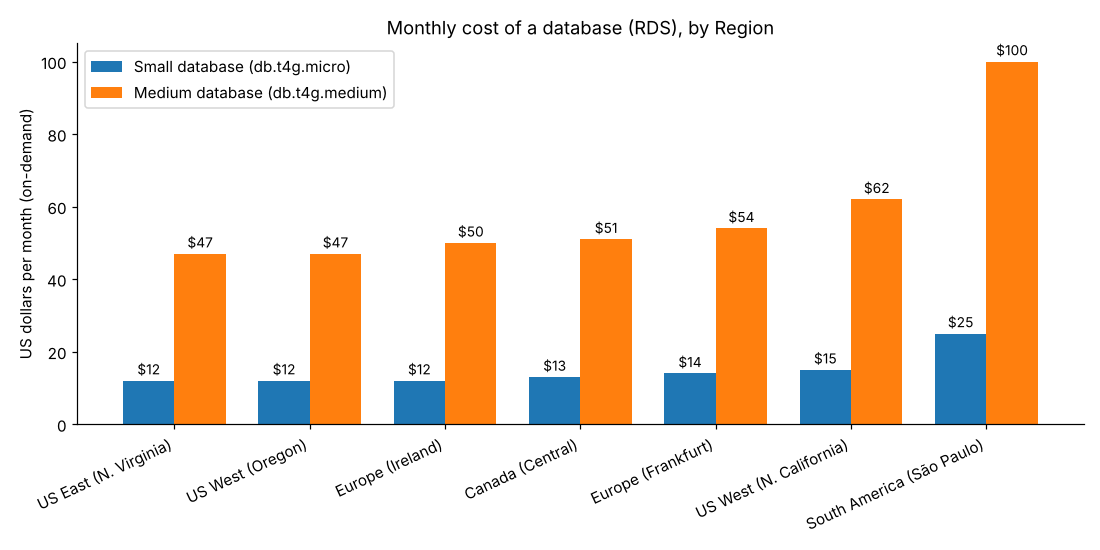

In [ ]:
import matplotlib.pyplot as plt

positions = list(range(len(prices)))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 5))
small  = ax.bar([p - width / 2 for p in positions], prices["small_usd_month"],  width, label="Small database (db.t4g.micro)")
medium = ax.bar([p + width / 2 for p in positions], prices["medium_usd_month"], width, label="Medium database (db.t4g.medium)")
ax.bar_label(small,  fmt="$%d", padding=2, fontsize=9)
ax.bar_label(medium, fmt="$%d", padding=2, fontsize=9)

ax.set_xticks(positions)
ax.set_xticklabels(prices["name"], rotation=25, ha="right")
ax.set_ylabel("US dollars per month (on-demand)")
ax.set_title("Monthly cost of a database (RDS), by Region")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

What do we learn?
- **N. Virginia and Oregon** are the cheapest here.
- **São Paulo costs about double** the Virginia price for the same database.
- The difference **grows with the size**: about 13 dollars more for the small one, more than 50 dollars more for the medium one.

### Another price: more safety also costs more
A database can have a **standby copy in a second AZ** (this is called **Multi-AZ**). If the first AZ fails, the copy takes over. You pay for two. In Ireland, for the medium database, the price per hour is 0.069 USD with one AZ and 0.138 USD with Multi-AZ (source: Spare Cores).

In [ ]:
HOURS_IN_MONTH = 730
single_az, multi_az = 0.069, 0.138     # USD per hour, db.t4g.medium in Europe (Ireland)

print(f"One AZ   : ${single_az * HOURS_IN_MONTH:6.2f} per month")
print(f"Multi-AZ : ${multi_az  * HOURS_IN_MONTH:6.2f} per month   ({multi_az / single_az:.0f}x)")

> **Also remember:** moving data **between AZs** and **between Regions** is usually charged too. Spreading everything everywhere is not always the best idea.

### Check prices yourself (no AWS account needed)
1. Open **calculator.aws** and choose **Create estimate**.
2. Add **Amazon RDS for MySQL**.
3. Choose the Region **US East (N. Virginia)**, a `db.t4g.micro` database, and write down the monthly price.
4. Change **only the Region** to **South America (São Paulo)**. See how much it changes.
5. Turn on **Multi-AZ** and watch the price go up.

---
## Part 8: How to choose a Region

The cheapest Region is not always the best. Think about these four things, in this order:

| # | Question | Why it matters |
|---|---|---|
| 1 | **Where are my users?** | The closer the Region, the faster the app answers |
| 2 | **Does the law say where the data must stay?** | Some data must stay in a country or continent |
| 3 | **Does the Region have the services I need?** | New services arrive in some Regions first |
| 4 | **How much does it cost?** | Compare the same service in the Regions that passed the first three questions |

And for **safety**: inside the Region you chose, use **at least two AZs** for anything that must not stop (servers behind a load balancer, database with Multi-AZ).

---
## Part 9: Clean-up

This lesson **created nothing** in AWS, so there is nothing to delete. We only remove the keys from this notebook's memory:

In [ ]:
for name in ["AWS_ACCESS_KEY_ID", "AWS_SECRET_ACCESS_KEY"]:
    os.environ.pop(name, None)
print("Keys removed from this session's memory.")

---
## Part 10: Exercises

1. **Using the CLI**, list only the Regions that are **not enabled** in your account.
2. Which Region enabled in your account has the **most AZs**? (Run the Part 3 bar cell again if you cleared the keys.)
3. Run `describe-availability-zones` in two different Regions. Compare the **ZoneIds**. What do you notice?
4. Use **calculator.aws** to compare a `db.t4g.micro` MySQL database in **N. Virginia** and **São Paulo**, then turn on **Multi-AZ** in each. Write the four prices.
5. A startup in Lisbon keeps customer data that **must stay in the European Union**. Which Region would you look at first, and why?

<details>
<summary><b>Show answers</b></summary>

1. `aws ec2 describe-regions --all-regions --query "Regions[?OptInStatus=='not-opted-in'].RegionName" --output text`
2. Look for the longest bar. In many accounts it is `us-east-1` (N. Virginia), which has up to 6 AZs. Your account may see fewer, and the number can change over time.
3. Each ZoneId starts with a short code of its Region (for example `euw1-az1` in Ireland and `use1-az1` in N. Virginia). The ZoneId identifies the real place, in the Region where you asked.
4. The numbers change over time, but São Paulo should come out around double, and Multi-AZ should be around double again.
5. Any **EU Region** satisfies the rule about keeping data in the EU (for example Ireland, Frankfurt or Spain). Among them, pick the one **closest to the users** that has the **services** you need, and then compare the **prices**. Spain (`eu-south-2`) is the closest to Lisbon, but it is an opt-in Region, so check that it has everything you need.

</details>

---
## Cheat sheet

| Term | In one sentence |
|---|---|
| **Region** | A place in the world with several AZs. Independent from other Regions |
| **Availability Zone (AZ)** | A part of a Region, made of one or more data centers. Use more than one for safety |
| **Data center** | The real building with servers. You cannot choose or see it |
| **Edge location** | A small site close to users that keeps copies of content. Not inside a Region |
| **Local Zone** | A small extension of a Region inside a big city |
| **ZoneName vs ZoneId** | Name is what you type. The ID points to the real place and can be compared between accounts |

| I want to… | Command |
|---|---|
| Know who I am | `aws sts get-caller-identity` |
| List my enabled Regions | `aws ec2 describe-regions` |
| List all Regions, including the off ones | `aws ec2 describe-regions --all-regions` |
| List the AZs of a Region | `aws ec2 describe-availability-zones --region eu-west-1` |
| List Local Zones | `aws ec2 describe-availability-zones --all-availability-zones --filters Name=zone-type,Values=local-zone` |
| See which AZ each subnet is in | `aws ec2 describe-subnets` |
| Compare prices | calculator.aws |